
#Caso de estudio: Predicción de diabetes con Python, visualización y redes neuronales

 Andres Hinojosa

* **Dataset:** Diabetes Kaggle (https://www.kaggle.com/datasets/datascikhan/diabetes)  archivo diabetes_large_dataset.csv



## Preguntas a responder

1. ¿Qué características presenta la población registrada en el dataset?
2. ¿Existen diferencias entre los grupos con y sin diabetes?
3. ¿Qué variables presentan mayor relación con la variable objetivo?
4. ¿Qué modelo de clasificación ofrece mejores resultados?
5. ¿Una red neuronal logra resultados competitivos frente a un modelo tradicional?

## Bloque 1. Carga e inspección de datos

Descargue el archivo CSV desde Kaggle (enlace al dataset) y cárguelo en Colab mediante un botón de carga.

### 1.A Librerías

In [2]:
#Importar librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Modelos y metricas
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

#Red neuronal
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

#Semilla para que los resultados se puedan repetir
semilla = 42
np.random.seed(semilla)
tf.random.set_seed(semilla)

### 1.B Carga del archivo con botón de carga

In [3]:
from google.colab import files

#Boton para subir el csv descargado de Kaggle
archivo = files.upload()

#Se toma el nombre del archivo que se subio
nombre_archivo = list(archivo.keys())[0]
print("Archivo cargado:", nombre_archivo)

df = pd.read_csv(nombre_archivo)

Saving diabetes_large_dataset.csv to diabetes_large_dataset.csv
Archivo cargado: diabetes_large_dataset.csv


### 1.C Muestre las Primeras 10 filas y las últimas 5

In [4]:
#Primeras 10 filas
df.head(10)

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes
5,P000006,R00000006,46.0,41-50,Female,Female,White,White,Divorced,Some College,...,2.5,81.5,82.2,79.5,83.4,1,0,0,0.0,No Diabetes
6,P000007,R00000007,73.0,71-90,Female,Female,Black,Black,Widowed,Bachelor,...,5.9,71.0,72.6,50.2,70.7,5,0,0,1.0,Type 2
7,P000008,R00000008,61.0,61-70,Male,Male,Mixed,Mixed,Married,Bachelor,...,4.2,66.2,65.7,90.6,74.4,3,2,0,0.0,No Diabetes
8,P000009,R00000009,42.0,41-50,Male,Male,Black,Black,Married,Some College,...,14.9,81.0,79.4,74.4,86.1,1,0,0,0.0,No Diabetes
9,P000010,R00000010,58.0,51-60,Male,Male,Asian,Asian,Married,High School,...,19.8,71.8,72.1,57.9,83.1,4,0,0,1.0,Type 2


In [6]:
#Ultimas 5 filas
df.tail(5)

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
99995,P099996,R00099996,46.0,41-50,Male,Male,Black,Black,Divorced,Bachelor,...,0.3,73.2,69.2,53.4,58.2,2,0,1,0.0,No Diabetes
99996,P099997,R00099997,41.0,41-50,Female,Female,Asian,Asian,Married,Some College,...,4.0,77.6,77.4,77.6,86.3,4,2,0,0.0,No Diabetes
99997,P099998,R00099998,56.0,51-60,Female,Female,White,White,Widowed,High School,...,0.0,94.0,96.4,58.7,83.4,0,1,0,0.0,No Diabetes
99998,P099999,R00099999,46.0,41-50,Female,Female,White,White,Married,Bachelor,...,7.6,64.9,67.2,55.8,60.5,4,3,0,0.0,No Diabetes
99999,P100000,R00100000,51.0,51-60,Female,Female,Native American,Native American,Married,High School,...,0.0,80.9,71.0,82.9,84.9,4,2,0,0.0,No Diabetes


### 1.D Determine el número de registros y columnas.

In [7]:
#Dimension del dataset
print("Numero de registros:", df.shape[0])
print("Numero de columnas:", df.shape[1])
print("")



Numero de registros: 100000
Numero de columnas: 209

Columnas por tipo de dato:
float64    102
object      92
int64       15
Name: count, dtype: int64


### 1.E Identifique los tipos de datos de cada columna.

In [15]:
#Cantidad de columnas por tipo de dato
print("Columnas por tipo de dato:")
print(df.dtypes.astype(str).value_counts())

Columnas por tipo de dato:
float64    102
object      92
int64       15
Name: count, dtype: int64


In [16]:
#Tipo de dato de cada columna (se muestran todas)
for columna in df.columns:
    print(columna, "=", df[columna].dtype)

patient_id = object
record_id = object
age = float64
age_group = object
sex = object
gender = object
ethnicity = object
race_group = object
marital_status = object
education_level = object
employment_status = object
occupation_category = object
income_level = object
annual_income = float64
household_size = int64
dependents = int64
residential_area_type = object
urban_rural = object
insurance_status = object
height_cm = float64
weight_kg = float64
bmi = float64
bmi_category = object
waist_circumference_cm = float64
hip_circumference_cm = float64
waist_to_hip_ratio = float64
body_fat_percentage = float64
lean_body_mass_kg = float64
body_surface_area = float64
resting_metabolic_rate = float64
fasting_glucose_mg_dl = float64
random_glucose_mg_dl = float64
post_meal_glucose_mg_dl = float64
two_hour_glucose_mg_dl = float64
glucose_variability = float64
hba1c_percent = float64
estimated_average_glucose_mg_dl = float64
fasting_insulin_uIU_ml = float64
c_peptide_ng_ml = float64
insulin_resistan

### 1.F Calcule la cantidad de valores nulos y duplicados.

In [10]:
#Valores nulos por columna (solo las que tienen nulos)
nulos = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "% del total": (df.isnull().sum() / len(df) * 100).round(2)
})
nulos = nulos[nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)

print("Columnas con valores nulos:", len(nulos), "de", df.shape[1])
print("Total de celdas nulas:", df.isnull().sum().sum())
print(nulos)

Columnas con valores nulos: 43 de 209
Total de celdas nulas: 306332
                              Nulos  % del total
age_at_menopause              82257        82.26
fasting_insulin_uIU_ml        10178        10.18
self_management_score         10177        10.18
urine_albumin_mg_g            10134        10.13
medication_adherence_percent  10054        10.05
folate_ng_ml                  10045        10.04
ferritin_ng_ml                10022        10.02
vitamin_d_ng_ml               10018        10.02
public_transport_access       10003        10.00
c_peptide_ng_ml                9948         9.95
vitamin_b12_pg_ml              9903         9.90
waist_circumference_cm         5120         5.12
hemoglobin_g_dl                5102         5.10
smoking_status                 5091         5.09
triglycerides_mg_dl            5045         5.04
ast_u_l                        5044         5.04
wbc_count                      5040         5.04
egfr_ml_min_1_73m2             5027         5.03
t

In [12]:
#Filas duplicadas completas
print("Filas duplicadas:", df.duplicated().sum())

#Duplicados ignorando los identificadores (mismo paciente con otro ID)
print("Duplicados sin contar patient_id y record_id:", df.drop(columns=["patient_id", "record_id"]).duplicated().sum())

#IDs de paciente repetidos
print("patient_id repetidos:", df["patient_id"].duplicated().sum())

Filas duplicadas: 0
Duplicados sin contar patient_id y record_id: 0
patient_id repetidos: 0


### 1.F Identifique cuál es la variable objetivo y explique por qué.

La variable objetivo es diabetes_status porque es la única columna que registra directamente si el paciente pertenece al grupo con diabetes (1) o sin diabetes (0), que es justo lo que la institución quiere estimar. Al tener solo dos valores, el problema es de clasificación binaria. Las demás columnas (edad, IMC, glucosa, presión, antecedentes, hábitos) describen al paciente y se usan como predictoras. Por otro lado teniamos diabetes_type que indica el tipo de diabetes (Tipo 1, Tipo 2, gestacional, otra), información que solo se conoce después del diagnóstico por lo que no se escogio como variable objetivo. Como es coherente con diabetes_status, solo se puede usar para recuperar los valores faltantes del objetivo, no para predecir.

In [17]:
#Comparacion de los registros
print(df[["diabetes_status", "diabetes_type"]].head(20))
print("")

    diabetes_status diabetes_type
0               NaN   No Diabetes
1               NaN   No Diabetes
2               1.0        Type 2
3               0.0   No Diabetes
4               0.0   No Diabetes
5               0.0   No Diabetes
6               1.0        Type 2
7               0.0   No Diabetes
8               0.0   No Diabetes
9               1.0        Type 2
10              1.0        Type 2
11              0.0   No Diabetes
12              1.0        Type 2
13              0.0   No Diabetes
14              0.0   No Diabetes
15              1.0        Type 2
16              1.0        Type 2
17              0.0   No Diabetes
18              0.0   No Diabetes
19              1.0        Type 2



### 1.G Diccionario de datos

El dataset tiene 209 columnas, así que el significado se organiza en un diccionario que ayude a entender cada atributo presente en el dataset

In [13]:
significados = {
    #Identificacion y demografia
    "patient_id": "Identificador del paciente",
    "record_id": "Identificador del registro",
    "age": "Edad en años",
    "age_group": "Rango de edad",
    "sex": "Sexo biologico",
    "gender": "Genero declarado",
    "ethnicity": "Etnia",
    "race_group": "Grupo racial (repite ethnicity)",
    "marital_status": "Estado civil",
    "education_level": "Nivel educativo",
    "employment_status": "Situacion laboral",
    "occupation_category": "Categoria de ocupacion",
    "income_level": "Nivel de ingresos (categoria)",
    "annual_income": "Ingreso anual",
    "household_size": "Personas en el hogar",
    "dependents": "Numero de dependientes",
    "residential_area_type": "Tipo de zona de residencia",
    "urban_rural": "Zona urbana / suburbana / rural (repite residential_area_type)",
    "insurance_status": "Tipo de seguro medico",
    #Medidas corporales
    "height_cm": "Estatura (cm)",
    "weight_kg": "Peso (kg)",
    "bmi": "Indice de masa corporal (kg/m2)",
    "bmi_category": "Categoria de IMC",
    "waist_circumference_cm": "Circunferencia de cintura (cm)",
    "hip_circumference_cm": "Circunferencia de cadera (cm)",
    "waist_to_hip_ratio": "Relacion cintura-cadera",
    "body_fat_percentage": "Porcentaje de grasa corporal",
    "lean_body_mass_kg": "Masa magra (kg)",
    "body_surface_area": "Superficie corporal (m2)",
    "resting_metabolic_rate": "Tasa metabolica en reposo (kcal/dia)",
    #Glucosa e insulina
    "fasting_glucose_mg_dl": "Glucosa en ayunas (mg/dl)",
    "random_glucose_mg_dl": "Glucosa aleatoria (mg/dl)",
    "post_meal_glucose_mg_dl": "Glucosa despues de comer (mg/dl)",
    "two_hour_glucose_mg_dl": "Glucosa a las 2 horas de una carga oral (mg/dl)",
    "glucose_variability": "Variabilidad de la glucosa",
    "hba1c_percent": "Hemoglobina glicosilada HbA1c (%)",
    "estimated_average_glucose_mg_dl": "Glucosa promedio estimada a partir de HbA1c (mg/dl)",
    "fasting_insulin_uIU_ml": "Insulina en ayunas (uUI/ml)",
    "c_peptide_ng_ml": "Peptido C (ng/ml)",
    "insulin_resistance_index": "Indice de resistencia a la insulina",
    #Presion y corazon
    "systolic_bp": "Presion arterial sistolica (mm Hg)",
    "diastolic_bp": "Presion arterial diastolica (mm Hg)",
    "pulse_pressure": "Presion de pulso (sistolica - diastolica)",
    "mean_arterial_pressure": "Presion arterial media (mm Hg)",
    "heart_rate": "Frecuencia cardiaca (lpm)",
    "resting_heart_rate": "Frecuencia cardiaca en reposo (lpm)",
    "hypertension_status": "Clasificacion de la presion arterial",
    #Lipidos
    "total_cholesterol_mg_dl": "Colesterol total (mg/dl)",
    "ldl_mg_dl": "Colesterol LDL (mg/dl)",
    "hdl_mg_dl": "Colesterol HDL (mg/dl)",
    "triglycerides_mg_dl": "Trigliceridos (mg/dl)",
    "vldl_mg_dl": "Colesterol VLDL (mg/dl)",
    "cholesterol_hdl_ratio": "Relacion colesterol total / HDL",
    "non_hdl_cholesterol": "Colesterol no HDL (mg/dl)",
    #Rinon
    "creatinine_mg_dl": "Creatinina (mg/dl)",
    "bun_mg_dl": "Nitrogeno ureico en sangre (mg/dl)",
    "egfr_ml_min_1_73m2": "Tasa de filtracion glomerular estimada",
    "urine_albumin_mg_g": "Albumina en orina (mg/g)",
    "urine_albumin_creatinine_ratio": "Relacion albumina/creatinina en orina",
    "proteinuria_status": "Presencia de proteina en orina",
    "kidney_disease_status": "Grado de enfermedad renal",
    #Higado
    "alt_u_l": "Enzima hepatica ALT (U/L)",
    "ast_u_l": "Enzima hepatica AST (U/L)",
    "alp_u_l": "Fosfatasa alcalina (U/L)",
    "bilirubin_mg_dl": "Bilirrubina (mg/dl)",
    "albumin_g_dl": "Albumina en sangre (g/dl)",
    "total_protein_g_dl": "Proteinas totales (g/dl)",
    "ggt_u_l": "Enzima GGT (U/L)",
    "fatty_liver_status": "Higado graso",
    #Hemograma
    "hemoglobin_g_dl": "Hemoglobina (g/dl)",
    "hematocrit_percent": "Hematocrito (%)",
    "rbc_count": "Globulos rojos",
    "wbc_count": "Globulos blancos",
    "platelet_count": "Plaquetas",
    "mcv_fl": "Volumen corpuscular medio (fL)",
    "mch_pg": "Hemoglobina corpuscular media (pg)",
    "mchc_g_dl": "Concentracion de hemoglobina corpuscular media (g/dl)",
    "neutrophil_percent": "Neutrofilos (%)",
    "lymphocyte_percent": "Linfocitos (%)",
    #Electrolitos, vitaminas y minerales
    "sodium_mmol_l": "Sodio en sangre (mmol/L)",
    "potassium_mmol_l": "Potasio en sangre (mmol/L)",
    "chloride_mmol_l": "Cloro en sangre (mmol/L)",
    "calcium_mg_dl": "Calcio (mg/dl)",
    "magnesium_mg_dl": "Magnesio (mg/dl)",
    "vitamin_d_ng_ml": "Vitamina D (ng/ml)",
    "vitamin_b12_pg_ml": "Vitamina B12 (pg/ml)",
    "folate_ng_ml": "Folato (ng/ml)",
    "uric_acid_mg_dl": "Acido urico (mg/dl)",
    "iron_ug_dl": "Hierro (ug/dl)",
    "ferritin_ng_ml": "Ferritina (ng/ml)",
    #Antecedentes familiares
    "family_history_diabetes": "Antecedente familiar de diabetes",
    "father_diabetes": "Padre con diabetes",
    "mother_diabetes": "Madre con diabetes",
    "sibling_diabetes": "Hermano(a) con diabetes",
    "family_history_cardiovascular_disease": "Antecedente familiar cardiovascular",
    "family_history_hypertension": "Antecedente familiar de hipertension",
    "family_history_obesity": "Antecedente familiar de obesidad",
    #Habitos
    "smoking_status": "Estado de tabaquismo",
    "smoking_frequency": "Frecuencia de consumo de tabaco",
    "cigarettes_per_day": "Cigarrillos por dia",
    "years_smoked": "Años fumando",
    "alcohol_use": "Consume alcohol",
    "alcohol_frequency": "Frecuencia de consumo de alcohol",
    "alcohol_units_per_week": "Unidades de alcohol por semana",
    "physical_activity_level": "Nivel de actividad fisica",
    "exercise_days_per_week": "Dias de ejercicio por semana",
    "exercise_minutes_per_week": "Minutos de ejercicio por semana",
    "sedentary_hours_per_day": "Horas sedentarias al dia",
    "daily_steps": "Pasos diarios",
    "sleep_hours": "Horas de sueño",
    "sleep_quality": "Calidad del sueño",
    "stress_level": "Nivel de estres",
    "screen_time_hours": "Horas de pantalla al dia",
    #Dieta
    "diet_quality_score": "Puntaje de calidad de la dieta",
    "daily_calorie_intake": "Calorias diarias",
    "carbohydrate_percent": "% de calorias de carbohidratos",
    "protein_percent": "% de calorias de proteina",
    "fat_percent": "% de calorias de grasa",
    "sugar_grams_per_day": "Azucar diaria (g)",
    "added_sugar_grams_per_day": "Azucar añadida diaria (g)",
    "fiber_grams_per_day": "Fibra diaria (g)",
    "sodium_mg_per_day": "Sodio en la dieta (mg/dia)",
    "fruit_servings_per_day": "Porciones de fruta al dia",
    "vegetable_servings_per_day": "Porciones de verdura al dia",
    "whole_grain_servings_per_day": "Porciones de granos integrales al dia",
    "processed_food_frequency": "Frecuencia de comida procesada",
    "fast_food_frequency": "Frecuencia de comida rapida",
    "sugary_drink_frequency": "Frecuencia de bebidas azucaradas",
    "breakfast_frequency": "Frecuencia de desayuno",
    "meal_frequency": "Comidas al dia",
    "diet_pattern": "Patron de dieta",
    #Enfermedades asociadas
    "hypertension": "Diagnostico de hipertension",
    "hyperlipidemia": "Diagnostico de hiperlipidemia",
    "cardiovascular_disease": "Enfermedad cardiovascular",
    "coronary_artery_disease": "Enfermedad coronaria",
    "stroke_history": "Antecedente de ACV",
    "kidney_disease": "Enfermedad renal",
    "liver_disease": "Enfermedad hepatica",
    "thyroid_disorder": "Trastorno de tiroides",
    "pcos_status": "Sindrome de ovario poliquistico",
    "sleep_apnea": "Apnea del sueño",
    "obesity_diagnosis": "Diagnostico de obesidad",
    "metabolic_syndrome": "Sindrome metabolico",
    "prediabetes_history": "Antecedente de prediabetes",
    "gestational_diabetes_history": "Antecedente de diabetes gestacional",
    #Diagnostico y tratamiento de diabetes (posterior al diagnostico)
    "previous_diabetes_diagnosis": "Diagnostico previo de diabetes",
    "diabetes_medication": "Toma medicamento para diabetes",
    "metformin_use": "Usa metformina",
    "insulin_use": "Usa insulina",
    "sulfonylurea_use": "Usa sulfonilureas",
    "sglt2_inhibitor_use": "Usa inhibidores SGLT2",
    "glp1_medication_use": "Usa agonistas GLP-1",
    "dpp4_inhibitor_use": "Usa inhibidores DPP-4",
    "blood_pressure_medication": "Toma medicamento para la presion",
    "statin_use": "Usa estatinas",
    "medication_adherence_percent": "Adherencia al tratamiento (%)",
    "glucose_monitoring_frequency": "Frecuencia de control de glucosa",
    "home_glucose_monitoring": "Mide la glucosa en casa",
    "continuous_glucose_monitor": "Usa monitor continuo de glucosa",
    "annual_checkup": "Hace chequeo anual",
    "doctor_visit_frequency": "Frecuencia de visitas al medico",
    "nutritionist_visits_per_year": "Visitas al nutricionista por año",
    "diabetes_education_received": "Recibio educacion en diabetes",
    "self_management_score": "Puntaje de autocuidado",
    "healthcare_access_score": "Puntaje de acceso a salud",
    #Complicaciones de la diabetes
    "diabetic_retinopathy": "Retinopatia diabetica",
    "diabetic_neuropathy": "Neuropatia diabetica",
    "diabetic_nephropathy": "Nefropatia diabetica",
    "diabetic_foot_problem": "Pie diabetico",
    "hypoglycemia_history": "Antecedente de hipoglucemia",
    "hyperglycemia_history": "Antecedente de hiperglucemia",
    "diabetic_ketoacidosis_history": "Antecedente de cetoacidosis diabetica",
    "cardiovascular_complication": "Complicacion cardiovascular",
    "diabetes_complication_count": "Numero de complicaciones de diabetes",
    #Salud de la mujer
    "pregnancy_status": "Estado de embarazo",
    "number_of_pregnancies": "Numero de embarazos",
    "menopause_status": "Estado de menopausia",
    "age_at_menopause": "Edad de la menopausia",
    #Entorno
    "healthcare_access": "Acceso a servicios de salud",
    "distance_to_healthcare_km": "Distancia al centro de salud (km)",
    "neighborhood_income_level": "Nivel de ingresos del barrio",
    "food_access_score": "Puntaje de acceso a alimentos",
    "air_quality_index": "Indice de calidad del aire",
    "environmental_risk_score": "Puntaje de riesgo ambiental",
    "walkability_score": "Puntaje de caminabilidad del barrio",
    "green_space_access": "Acceso a zonas verdes",
    "public_transport_access": "Acceso a transporte publico",
    "community_health_resources": "Recursos de salud en la comunidad",
    "country": "Pais",
    "region": "Region",
    "state_province": "Estado o provincia",
    "city_category": "Tipo de ciudad",
    "climate_zone": "Zona climatica",
    "urbanization_level": "Nivel de urbanizacion",
    #Puntajes calculados
    "cardiovascular_risk_score": "Puntaje de riesgo cardiovascular",
    "metabolic_risk_score": "Puntaje de riesgo metabolico",
    "obesity_risk_score": "Puntaje de riesgo de obesidad",
    "hypertension_risk_score": "Puntaje de riesgo de hipertension",
    "kidney_risk_score": "Puntaje de riesgo renal",
    "diabetes_risk_score": "Puntaje de riesgo de diabetes",
    "overall_health_score": "Puntaje de salud general",
    "physical_health_score": "Puntaje de salud fisica",
    "mental_wellbeing_score": "Puntaje de bienestar mental",
    "quality_of_life_score": "Puntaje de calidad de vida",
    "chronic_condition_count": "Numero de enfermedades cronicas",
    "hospitalization_history": "Numero de hospitalizaciones",
    "emergency_visit_history": "Numero de visitas a urgencias",
    #Objetivo
    "diabetes_status": "VARIABLE OBJETIVO: 1 = con diabetes, 0 = sin diabetes",
    "diabetes_type": "Tipo de diabetes (se conoce despues del diagnostico)"
}

diccionario = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Significado": [significados.get(col, "Sin descripcion") for col in df.columns]
})

pd.set_option("display.max_rows", 250)
pd.set_option("display.max_colwidth", 80)
diccionario

,Variable,Tipo,Significado
0,patient_id,object,Identificador del paciente
1,record_id,object,Identificador del registro
2,age,float64,Edad en años
3,age_group,object,Rango de edad
4,sex,object,Sexo biologico
5,gender,object,Genero declarado
6,ethnicity,object,Etnia
7,race_group,object,Grupo racial (repite ethnicity)
8,marital_status,object,Estado civil
9,education_level,object,Nivel educativo


### Reto Bloque 1: Elabore una función que reciba un DataFrame e imprima un resumen general de su estructura y calidad.

La función recibe cualquier DataFrame y muestra su estructura y calidad: tamaño, tipos, nulos, duplicados, columnas con más faltantes y columnas que parecen identificadores.

In [14]:
def resumen_dataset(datos):
    print("RESUMEN GENERAL DEL DATASET")
    print("Registros:", datos.shape[0])
    print("Columnas:", datos.shape[1])
    print("Columnas numericas:", len(datos.select_dtypes(include="number").columns))
    print("Columnas de texto:", len(datos.select_dtypes(exclude="number").columns))
    print("Filas duplicadas:", datos.duplicated().sum())
    print("Total de celdas nulas:", datos.isnull().sum().sum())
    print("Columnas con al menos un nulo:", (datos.isnull().sum() > 0).sum())
    print("")

    #Las 10 columnas con mas faltantes
    print("Top 10 columnas con mas nulos (%):")
    porcentaje_nulos = (datos.isnull().sum() / len(datos) * 100).round(2)
    print(porcentaje_nulos.sort_values(ascending=False).head(10))
    print("")

    #Columnas donde cada valor es distinto (posibles identificadores)
    print("Posibles identificadores (todos los valores unicos):")
    for columna in datos.columns:
        if datos[columna].nunique() == len(datos):
            print("-", columna)
    print("")

    #Columnas con un solo valor (no aportan informacion)
    print("Columnas con un solo valor:")
    for columna in datos.columns:
        if datos[columna].nunique() <= 1:
            print("-", columna)

resumen_dataset(df)

RESUMEN GENERAL DEL DATASET
Registros: 100000
Columnas: 209
Columnas numericas: 117
Columnas de texto: 92
Filas duplicadas: 0
Total de celdas nulas: 306332
Columnas con al menos un nulo: 43

Top 10 columnas con mas nulos (%):
age_at_menopause                82.26
self_management_score           10.18
fasting_insulin_uIU_ml          10.18
urine_albumin_mg_g              10.13
medication_adherence_percent    10.05
folate_ng_ml                    10.04
ferritin_ng_ml                  10.02
vitamin_d_ng_ml                 10.02
public_transport_access         10.00
c_peptide_ng_ml                  9.95
dtype: float64

Posibles identificadores (todos los valores unicos):
- patient_id
- record_id

Columnas con un solo valor:


##Bloque 2 Limpieza y transformacion

###2.A duplicados

In [18]:
filas_antes = len(df)
df = df.drop_duplicates()
print("Filas antes:", filas_antes)
print("Filas despues:", len(df))
print("Filas eliminadas:", filas_antes - len(df))

Filas antes: 100000
Filas despues: 100000
Filas eliminadas: 0


**Justificación:**

 Se revisaron duplicados completos, duplicados ignorando los IDs y patient_id repetidos; en los tres casos el resultado fue 0. De todas formas se deja drop_duplicates() porque un duplicado es el mismo paciente contado dos veces: pesaría el doble y podría quedar una copia en entrenamiento y otra en prueba, inflando las métricas. Como no había duplicados, el paso no cambia nada pero queda documentado.

### 2.B Selección de variables y fuga de información

El dataset tiene 209 columnas, pero **no todas se pueden usar** para predecir la diabetes. Muchas columnas solo existen *porque* el paciente ya fue diagnosticado; si se usan, el modelo "hace trampa": aprende a reconocer el tratamiento o las complicaciones, no el riesgo.

In [19]:
#Correlacion de algunas columnas sospechosas con el objetivo
sospechosas = ["diabetes_risk_score", "chronic_condition_count", "overall_health_score",
               "diabetes_complication_count", "kidney_risk_score", "metabolic_risk_score"]

print("Correlacion con", objetivo)
for columna in sospechosas:
    print(columna, ":", round(df[columna].corr(df[objetivo]), 3))

Correlacion con diabetes_status
diabetes_risk_score : 0.709
chronic_condition_count : 0.602
overall_health_score : -0.62
diabetes_complication_count : 0.327
kidney_risk_score : 0.41
metabolic_risk_score : 0.385


Con lógica sencilla se eligen **14 predictoras** que se conocen *antes* del diagnóstico: medidas corporales, laboratorios básicos, presión arterial, antecedentes y hábitos. Así el modelo es honesto y más fácil de explicar.

In [21]:
#Variables numericas elegidas
variables_numericas = ["age", "bmi", "waist_circumference_cm", "fasting_glucose_mg_dl",
                       "hba1c_percent", "systolic_bp", "diastolic_bp",
                       "hdl_mg_dl", "triglycerides_mg_dl"]

#Variables categoricas elegidas
variables_categoricas = ["sex", "family_history_diabetes", "hypertension",
                         "physical_activity_level", "smoking_status"]

variables_modelo = variables_numericas + variables_categoricas

#Se trabaja con una copia que solo tiene las columnas necesarias
datos = df[variables_modelo + ["gender", "diabetes_type", objetivo]].copy()
print("Forma de la tabla de trabajo:", datos.shape)
print(datos.head(10))

Forma de la tabla de trabajo: (100000, 17)
    age    bmi  waist_circumference_cm  fasting_glucose_mg_dl  hba1c_percent  \
0  57.0  25.55                    83.9                   88.1           4.55   
1  47.0  20.06                    61.3                   99.6           4.72   
2  59.0  17.53                    72.7                   97.0           4.95   
3  72.0  36.32                    90.1                  106.9           4.82   
4  46.0  28.34                    91.1                  112.5           4.68   
5  46.0  28.22                    78.6                   80.6           4.39   
6  73.0  22.71                    76.4                   82.3           4.00   
7  61.0  23.19                    74.6                  115.9           5.09   
8  42.0  16.64                    78.5                   60.0           4.17   
9  58.0  27.78                    85.0                  120.6           4.97   

   systolic_bp  diastolic_bp  hdl_mg_dl  triglycerides_mg_dl     sex  \
0   

### Variables predictoras elegidas

| Variable | Tipo | Qué indica |
|---|---|---|
| `age` | Numérica | Edad del paciente en años |
| `bmi` | Numérica | Índice de masa corporal (kg/m²) |
| `waist_circumference_cm` | Numérica | Circunferencia de cintura, mide grasa abdominal (cm) |
| `fasting_glucose_mg_dl` | Numérica | Glucosa en sangre en ayunas (mg/dl) |
| `hba1c_percent` | Numérica | Hemoglobina glicosilada, promedio de glucosa de los últimos 2-3 meses (%) |
| `systolic_bp` | Numérica | Presión arterial sistólica (mm Hg) |
| `diastolic_bp` | Numérica | Presión arterial diastólica (mm Hg) |
| `hdl_mg_dl` | Numérica | Colesterol HDL o "bueno" (mg/dl) |
| `triglycerides_mg_dl` | Numérica | Triglicéridos, grasa en sangre (mg/dl) |
| `sex` | Categórica | Sexo biológico (Female = 0, Male = 1) |
| `family_history_diabetes` | Categórica | Si tiene familiares con diabetes (No = 0, Yes = 1) |
| `hypertension` | Categórica | Si tiene diagnóstico de hipertensión (No = 0, Yes = 1) |
| `physical_activity_level` | Categórica | Nivel de actividad física (0 = Sedentario … 4 = Extremadamente activo) |
| `smoking_status` | Categórica | Tabaquismo (0 = Nunca, 1 = Exfumador, 2 = Fumador actual) |

### 2.C Valores faltantes de la variable objetivo

In [25]:
objetivo = "diabetes_status"

print("Objetivo nulo antes:", datos[objetivo].isnull().sum())

#Si diabetes_status es nulo pero diabetes_type dice el diagnostico, se recupera
for i in datos.index[datos[objetivo].isnull()]:
    tipo = datos.loc[i, "diabetes_type"]
    if tipo == "No Diabetes":
        datos.loc[i, objetivo] = 0
    elif pd.notnull(tipo):
        datos.loc[i, objetivo] = 1

print("Objetivo nulo despues de recuperar con diabetes_type:", datos[objetivo].isnull().sum())

#Los que siguen sin objetivo no sirven para entrenar ni evaluar
datos = datos.dropna(subset=[objetivo]).copy()
datos[objetivo] = datos[objetivo].astype(int)
print("Registros que quedan:", len(datos))

Objetivo nulo antes: 2020
Objetivo nulo despues de recuperar con diabetes_type: 42
Registros que quedan: 99958


**Estrategia:** Como diabetes_type es coherente con diabetes_status, se usa para recuperar el valor cuando existe. Los pocos registros que no tienen ninguna de las dos se eliminan, porque sin etiqueta no sirven para entrenar ni para evaluar.

### 2.D Faltantes de las variables predictoras

In [26]:
print("Nulos en sex antes:", datos["sex"].isnull().sum())

#Si falta sex pero gender es Male o Female, se usa ese valor
for i in datos.index[datos["sex"].isnull()]:
    if datos.loc[i, "gender"] in ["Male", "Female"]:
        datos.loc[i, "sex"] = datos.loc[i, "gender"]

print("Nulos en sex despues de usar gender:", datos["sex"].isnull().sum())
print("")

print("Nulos restantes en las variables del modelo:")
print(datos[variables_modelo].isnull().sum())

Nulos en sex antes: 2004
Nulos en sex despues de usar gender: 27

Nulos restantes en las variables del modelo:
age                        1993
bmi                        2022
waist_circumference_cm     5119
fasting_glucose_mg_dl      2061
hba1c_percent              1945
systolic_bp                1947
diastolic_bp               2093
hdl_mg_dl                  4954
triglycerides_mg_dl        5042
sex                          27
family_history_diabetes       0
hypertension                  0
physical_activity_level    5003
smoking_status             5090
dtype: int64


**Estrategia según el tipo de variable:**

* **sex:** se completa con gender cuando dice Male o Female (es información real del mismo paciente). Los que dicen "Non-Bi" quedan como faltantes.
* **Numéricas:** se rellenan con la **mediana**, que no se deja afectar por valores extremos (por ejemplo triglicéridos o glucosa muy altos).
* **Categóricas:** después de codificarlas como números se rellenan con la mediana, que en variables de 0/1 equivale al valor más frecuente.


### 2.E Revisión de valores inválidos

In [27]:
#Regla 1: la presion sistolica siempre debe ser mayor que la diastolica
presion_invalida = datos["systolic_bp"] <= datos["diastolic_bp"]
print("Registros con sistolica <= diastolica:", presion_invalida.sum())

#Regla 2: un IMC menor a 12 es practicamente incompatible con la vida en adultos
imc_invalido = datos["bmi"] < 12
print("Registros con IMC < 12:", imc_invalido.sum())

#Regla 3: valores negativos en medidas clinicas
for columna in variables_numericas:
    print(columna, "-> negativos:", (datos[columna] < 0).sum(), "| minimo:", datos[columna].min(), "| maximo:", datos[columna].max())

#Regla 4: glucosa en ayunas y HbA1c separadas del resto de la distribucion
print("")
print("Glucosa en ayunas por rangos:")
print(pd.cut(datos["fasting_glucose_mg_dl"], [0, 150, 200, 250, 300, 400]).value_counts().sort_index())
print("")
print("HbA1c por rangos:")
print(pd.cut(datos["hba1c_percent"], [0, 5, 6, 6.5, 10, 14]).value_counts().sort_index())

glucosa_sospechosa = datos["fasting_glucose_mg_dl"] > 250
hba1c_sospechosa = datos["hba1c_percent"] > 10

print("")
print("Diagnostico de los pacientes con glucosa > 250:")
print(datos.loc[glucosa_sospechosa, objetivo].value_counts())
print("Diagnostico de los pacientes con HbA1c > 10:")
print(datos.loc[hba1c_sospechosa, objetivo].value_counts())
print("Registros que tienen ambos valores sospechosos a la vez:", (glucosa_sospechosa & hba1c_sospechosa).sum())

#Valores pegados al minimo de medicion
print("")
print("Pacientes con glucosa exactamente en 60 (minimo):", (datos["fasting_glucose_mg_dl"] == 60).sum())

#Otras observaciones del dataset original
print("")
print("Valores de gender:", df["gender"].unique())
print("Valores de hospitalization_history:", df["hospitalization_history"].unique())

Registros con sistolica <= diastolica: 24
Registros con IMC < 12: 85
age -> negativos: 0 | minimo: 18.0 | maximo: 90.0
bmi -> negativos: 0 | minimo: 9.94 | maximo: 59.69250883930601
waist_circumference_cm -> negativos: 0 | minimo: 50.0 | maximo: 140.0
fasting_glucose_mg_dl -> negativos: 0 | minimo: 60.0 | maximo: 399.04277347875336
hba1c_percent -> negativos: 0 | minimo: 4.0 | maximo: 13.98639002530302
systolic_bp -> negativos: 0 | minimo: 80.0 | maximo: 219.86311766449643
diastolic_bp -> negativos: 0 | minimo: 50.0 | maximo: 118.0
hdl_mg_dl -> negativos: 0 | minimo: 15.0 | maximo: 98.7
triglycerides_mg_dl -> negativos: 0 | minimo: 30.0 | maximo: 598.5594407514798

Glucosa en ayunas por rangos:
fasting_glucose_mg_dl
(0, 150]      95340
(150, 200]     2356
(200, 250]        1
(250, 300]       52
(300, 400]      148
Name: count, dtype: int64

HbA1c por rangos:
hba1c_percent
(0.0, 5.0]      72189
(5.0, 6.0]      25526
(6.0, 6.5]         98
(6.5, 10.0]         0
(10.0, 14.0]      200
Name:

In [28]:
#Ejemplos de registros con presion invalida
datos.loc[presion_invalida, ["systolic_bp", "diastolic_bp"]].head()

,systolic_bp,diastolic_bp
12374,89.0,91.0
23572,89.0,92.0
29731,92.0,92.0
31753,92.0,92.0
37603,89.0,93.0


In [29]:
#No se eliminan las filas: solo se marca como faltante el valor que no tiene sentido
datos.loc[presion_invalida, ["systolic_bp", "diastolic_bp"]] = np.nan
datos.loc[imc_invalido, "bmi"] = np.nan
datos.loc[glucosa_sospechosa, "fasting_glucose_mg_dl"] = np.nan
datos.loc[hba1c_sospechosa, "hba1c_percent"] = np.nan

print("Presion invalida:", presion_invalida.sum(), "registros")
print("IMC invalido:", imc_invalido.sum(), "registros")
print("Glucosa > 250:", glucosa_sospechosa.sum(), "registros")
print("HbA1c > 10:", hba1c_sospechosa.sum(), "registros")

Presion invalida: 24 registros
IMC invalido: 85 registros
Glucosa > 250: 200 registros
HbA1c > 10: 200 registros


**Hallazgos y decisión:**

* Hay registros con sistólica menor o igual que la diastólica (fisiológicamente imposible) y registros con IMC menor a 12. **No se elimina la fila**: solo ese valor se convierte en faltante y luego se rellena con la mediana. Así se conserva el resto de la información del paciente. Lo mismo se hace con los casos siguientes.
* **Glucosa en ayunas > 250 mg/dl y HbA1c > 10%:** forman un grupo aislado (casi no hay pacientes entre 200 y 250 de glucosa, ni entre 6.5 y 10 de HbA1c) y la mayoría está registrada como **sin diabetes**, lo cual es clínicamente incoherente: una glucosa en ayunas de 300 o una HbA1c de 12% cumplen por sí solas el criterio de diabetes. Parecen errores de registro, así que se tratan como faltantes. La regla se basa en el valor clínico y en el salto de la distribución, no en el diagnóstico, para no usar el objetivo al limpiar.
* Hay alrededor de 2.000 pacientes con glucosa exactamente en 60 mg/dl, el mínimo del dataset; parece un límite de registro (valores más bajos se guardaron como 60). Se dejan, pero se reporta como limitación.
* No hay valores negativos en las variables elegidas.
* `gender` tiene la categoría "Non-Bi", que parece un texto cortado ("Non-Binary").
* `hospitalization_history` guarda números como texto y usa "4+", así que no se puede tratar como numérica sin transformarla. No se usa en el modelo.
* `race_group` repite `ethnicity` y `urban_rural` repite `residential_area_type` (columnas redundantes).

### 2.F Valores atípicos con diagramas de caja

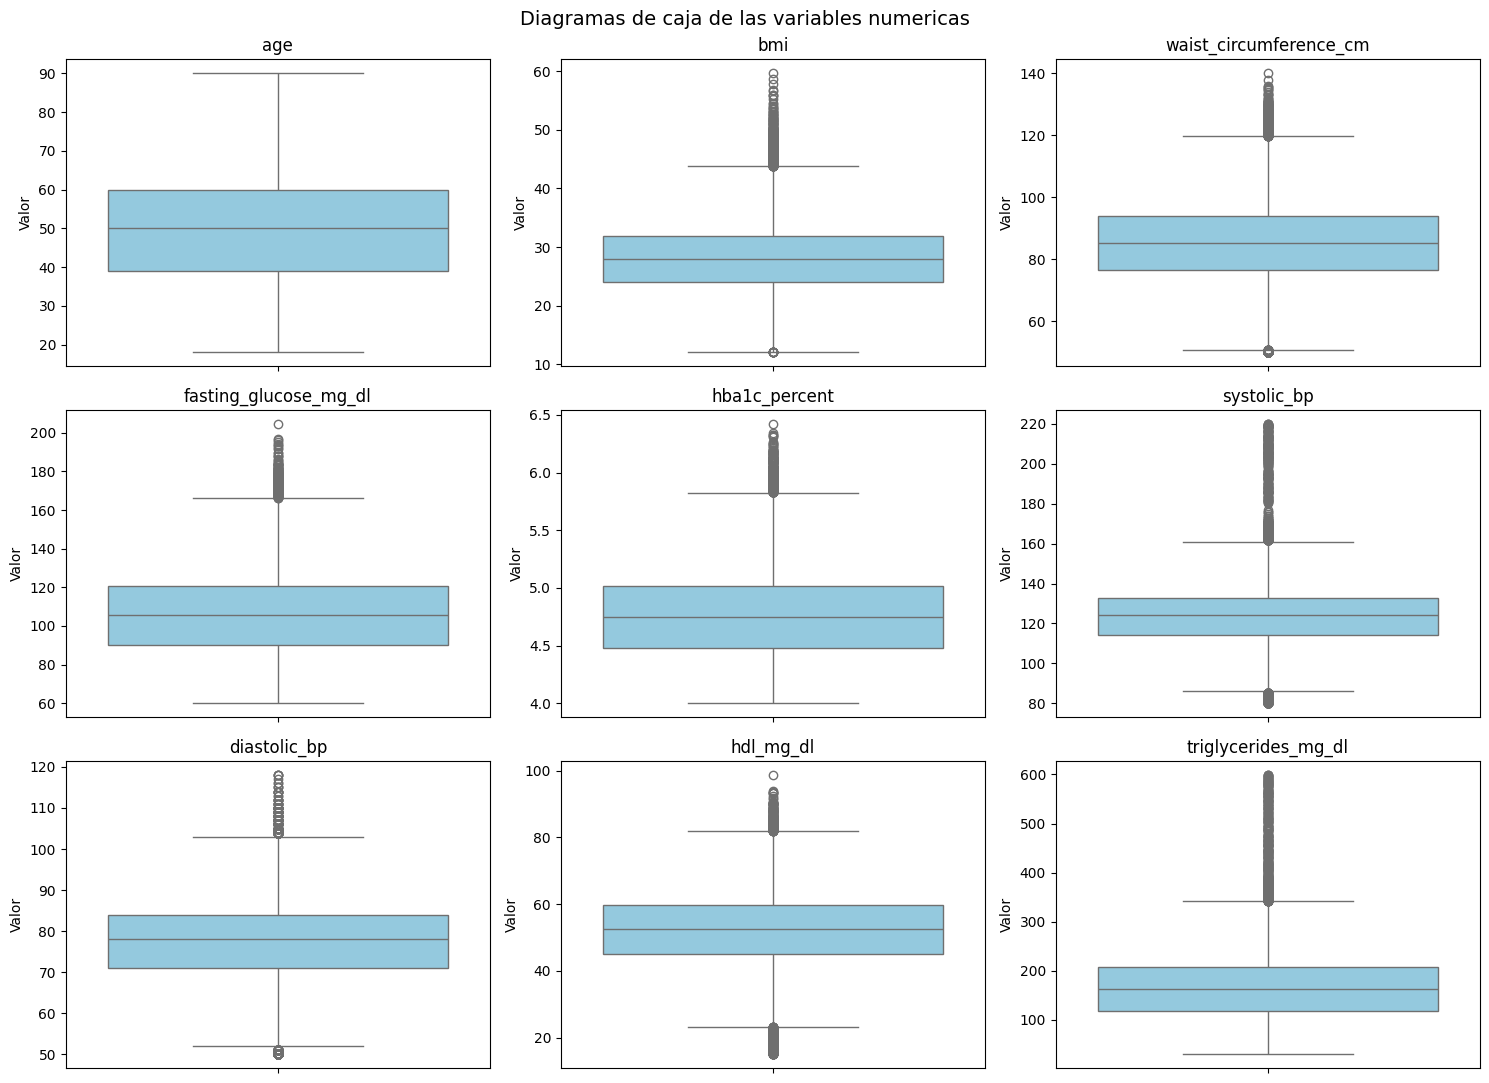

In [30]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 11))
ejes = ejes.flatten()

for i in range(len(variables_numericas)):
    columna = variables_numericas[i]
    sns.boxplot(y=datos[columna], ax=ejes[i], color="skyblue")
    ejes[i].set_title(columna)
    ejes[i].set_ylabel("Valor")

plt.suptitle("Diagramas de caja de las variables numericas", fontsize=14)
plt.tight_layout()
plt.show()

In [31]:
#Conteo de atipicos con la regla del rango intercuartilico (IQR)
print("Variable | Limite inferior | Limite superior | Atipicos | %")
for columna in variables_numericas:
    q1 = datos[columna].quantile(0.25)
    q3 = datos[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    atipicos = ((datos[columna] < limite_inf) | (datos[columna] > limite_sup)).sum()
    print(columna, "|", round(limite_inf, 2), "|", round(limite_sup, 2), "|", atipicos, "|", round(atipicos / len(datos) * 100, 2))

Variable | Limite inferior | Limite superior | Atipicos | %
age | 7.5 | 91.5 | 0 | 0.0
bmi | 12.02 | 43.86 | 656 | 0.66
waist_circumference_cm | 50.9 | 119.7 | 568 | 0.57
fasting_glucose_mg_dl | 44.8 | 166.4 | 325 | 0.33
hba1c_percent | 3.67 | 5.83 | 371 | 0.37
systolic_bp | 85.5 | 161.5 | 713 | 0.71
diastolic_bp | 51.5 | 103.5 | 663 | 0.66
hdl_mg_dl | 23.15 | 81.95 | 628 | 0.63
triglycerides_mg_dl | -15.75 | 342.25 | 544 | 0.54


**Decisión sobre atípicos:** no se eliminan. Los atípicos que quedan (glucosa alta, IMC alto, presión alta, triglicéridos altos) son valores raros pero clínicamente posibles, y muchos son **justamente** típicos de un paciente con diabetes. Quitarlos borraría información del grupo que más interesa. Los únicos valores modificados son los inválidos del paso 2.E.

### 2.G Variables categóricas y codificación

In [32]:
#Columnas de texto en el dataset original
categoricas_originales = df.select_dtypes(exclude="number").columns
print("Columnas de texto en el dataset completo:", len(categoricas_originales))
print("")

#Valores de las categoricas elegidas
for columna in variables_categoricas:
    print(columna, "->", datos[columna].unique())

Columnas de texto en el dataset completo: 92

sex -> ['Male' 'Female' nan]
family_history_diabetes -> ['No' 'Yes']
hypertension -> ['No' 'Yes']
physical_activity_level -> ['Lightly Active' 'Sedentary' 'Moderately Active' 'Extremely Active'
 'Very Active' nan]
smoking_status -> ['Never' 'Former' 'Current' nan]


De las variables elegidas, las 5 categóricas están en texto y **necesitan codificación**, porque los modelos solo trabajan con números. Se usa `map` con lógica sencilla:

* **Binarias** (`sex`, `family_history_diabetes`, `hypertension`): 0 y 1.
* **Ordinales** (`physical_activity_level`, `smoking_status`): tienen un orden natural, así que se numeran de menor a mayor. No hace falta One-Hot.

In [33]:
codificacion = {
    "sex": {"Female": 0, "Male": 1},
    "family_history_diabetes": {"No": 0, "Yes": 1},
    "hypertension": {"No": 0, "Yes": 1},
    "physical_activity_level": {"Sedentary": 0, "Lightly Active": 1, "Moderately Active": 2,
                                "Very Active": 3, "Extremely Active": 4},
    "smoking_status": {"Never": 0, "Former": 1, "Current": 2}
}

#Se guarda una copia con texto para las graficas
datos_texto = datos.copy()

for columna in variables_categoricas:
    datos[columna] = datos[columna].map(codificacion[columna])

print(datos[variables_categoricas].head())
print("")
print("Nulos despues de codificar (se rellenan en el Bloque 4):")
print(datos[variables_categoricas].isnull().sum())

   sex  family_history_diabetes  hypertension  physical_activity_level  \
0  1.0                        0             0                      1.0   
1  0.0                        0             0                      0.0   
2  1.0                        0             0                      2.0   
3  0.0                        0             1                      4.0   
4  1.0                        0             0                      2.0   

   smoking_status  
0             0.0  
1             1.0  
2             0.0  
3             0.0  
4             2.0  

Nulos despues de codificar (se rellenan en el Bloque 4):
sex                          27
family_history_diabetes       0
hypertension                  0
physical_activity_level    5003
smoking_status             5090
dtype: int64


### 2.H Separar X (predictoras) y y (objetivo)

In [34]:
#X caracteristicas, y lo que queremos predecir
X = datos[variables_modelo]
y = datos[objetivo]

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (99958, 14)
Forma de y: (99958,)


### Reto Bloque 2: ¿por qué el escalado se ajusta solo con entrenamiento?

StandardScaler calcula el promedio y la desviación estándar de cada variable. Si se ajusta con **todo** el dataset, esos valores incluyen información del conjunto de prueba, y el modelo "ve" indirectamente datos que se supone no conoce. Esto es fuga de datos hace que las métricas de prueba salgan más optimistas de lo que serían con pacientes nuevos.

El orden correcto es: dividir en entrenamiento y prueba `fit_transform` con entrenamiento solo `transform` en prueba. El conjunto de prueba se trata como pacientes que llegan después y que el modelo nunca vio. Lo mismo aplica a la mediana usada para rellenar faltantes.

## Bloque 3. Análisis exploratorio y visualización

Se crea una columna con etiquetas de texto solo para que las gráficas sean más fáciles de leer.

In [35]:
datos["Diagnostico"] = datos[objetivo].map({0: "Sin diabetes", 1: "Con diabetes"})
datos_texto["Diagnostico"] = datos["Diagnostico"]
colores = {"Sin diabetes": "#2196F3", "Con diabetes": "#F44336"}

#Descripcion general de la poblacion
print(datos[variables_numericas].describe().round(2).T)
print("")
print("Distribucion por sexo:")
print(datos_texto["sex"].value_counts(normalize=True).round(3) * 100)

                          count    mean    std   min     25%     50%     75%  \
age                     97965.0   49.60  14.73  18.0   39.00   50.00   60.00   
bmi                     97851.0   28.05   5.93  12.0   23.96   27.88   31.92   
waist_circumference_cm  94839.0   85.32  12.74  50.0   76.70   85.20   93.90   
fasting_glucose_mg_dl   97697.0  105.74  22.08  60.0   90.40  105.50  120.80   
hba1c_percent           97813.0    4.75   0.39   4.0    4.48    4.75    5.02   
systolic_bp             97987.0  123.68  14.16  80.0  114.00  124.00  133.00   
diastolic_bp            97841.0   77.60   9.64  50.0   71.00   78.00   84.00   
hdl_mg_dl               95004.0   52.51  10.85  15.0   45.20   52.50   59.90   
triglycerides_mg_dl     94916.0  164.25  66.48  30.0  118.50  162.90  208.00   

                           max  
age                      90.00  
bmi                      59.69  
waist_circumference_cm  140.00  
fasting_glucose_mg_dl   204.40  
hba1c_percent             6.42  
s

### 3.A Distribución de la variable objetivo (barras)

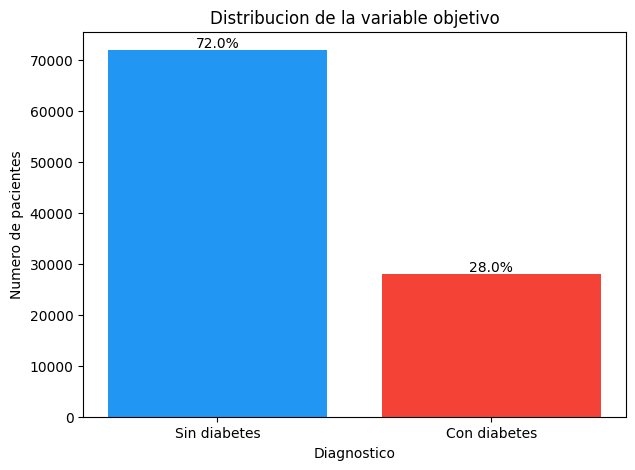

In [36]:
conteo = datos["Diagnostico"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(conteo.index, conteo.values, color=[colores[c] for c in conteo.index])

#Escribir el porcentaje encima de cada barra
for i in range(len(conteo)):
    porcentaje = round(conteo.values[i] / conteo.sum() * 100, 1)
    plt.text(i, conteo.values[i] + 500, str(porcentaje) + "%", ha="center")

plt.title("Distribucion de la variable objetivo")
plt.xlabel("Diagnostico")
plt.ylabel("Numero de pacientes")
plt.show()

* **Patrón:** hay 71.974 pacientes sin diabetes (72%) y 27.984 con diabetes (28%); por cada paciente con diabetes hay aproximadamente 2.6 sin diabetes.
* **Información:** muestra cuántos pacientes hay en cada clase y si están balanceadas.
* **Limitación:** solo cuenta casos; no explica por qué un paciente tiene o no diabetes.

### Reto Bloque 3: ¿la variable objetivo está desbalanceada?

Sí, está **desbalanceada**: 72% sin diabetes y 28% con diabetes. No es extremo, pero afecta la evaluación

### 3.B Histogramas de glucosa en ayunas e IMC por diagnóstico

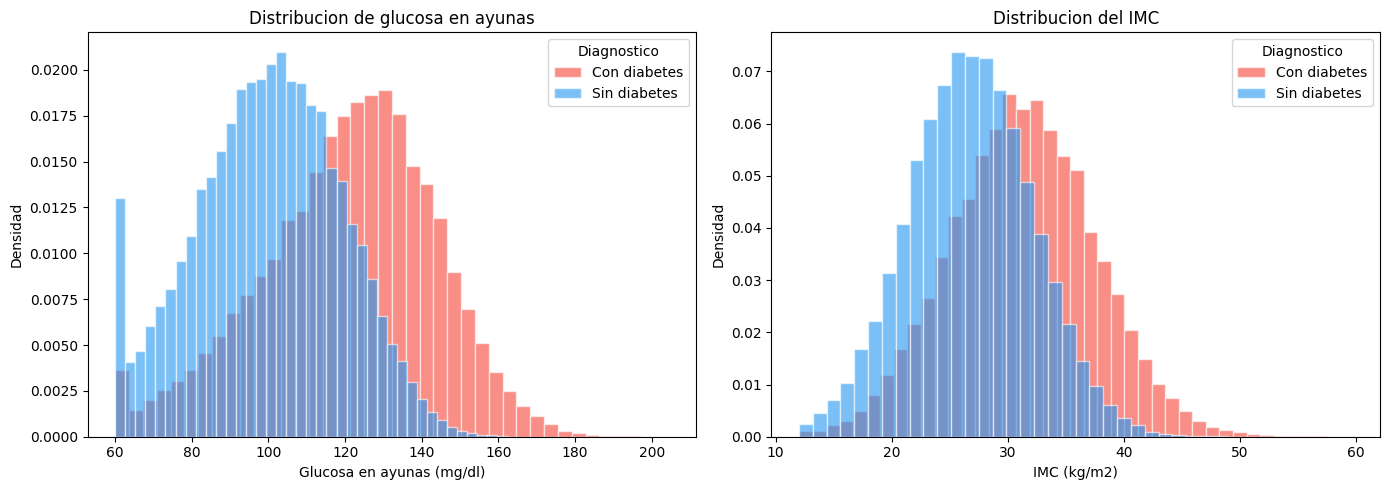

In [37]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for etiqueta, grupo in datos.groupby("Diagnostico"):
    ejes[0].hist(grupo["fasting_glucose_mg_dl"].dropna(), bins=40, alpha=0.6, density=True,
                 label=etiqueta, color=colores[etiqueta], edgecolor="white")
    ejes[1].hist(grupo["bmi"].dropna(), bins=40, alpha=0.6, density=True,
                 label=etiqueta, color=colores[etiqueta], edgecolor="white")

ejes[0].set_title("Distribucion de glucosa en ayunas")
ejes[0].set_xlabel("Glucosa en ayunas (mg/dl)")
ejes[0].set_ylabel("Densidad")
ejes[0].legend(title="Diagnostico")

ejes[1].set_title("Distribucion del IMC")
ejes[1].set_xlabel("IMC (kg/m2)")
ejes[1].set_ylabel("Densidad")
ejes[1].legend(title="Diagnostico")

plt.tight_layout()
plt.show()

* **Patrón:** en glucosa en ayunas el grupo con diabetes está desplazado a la derecha: los sin diabetes se concentran entre 80 y 115 mg/dl y los con diabetes entre 115 y 150; por encima de ~150 casi solo hay pacientes con diabetes. En el IMC el desplazamiento es parecido (pico cerca de 27 vs 31), con una cola larga de obesidad en el grupo con diabetes. También se ve una barra alta en 60 mg/dl, el valor mínimo registrado.
* **Información:** muestra la forma de cada distribución y cuánto se superponen los grupos.
* **Limitación:** al usar densidad no se ven las cantidades absolutas; además la superposición indica que ninguna variable separa sola a los grupos.

### 3.C Diagrama de caja: glucosa en ayunas en pacientes con y sin diabetes

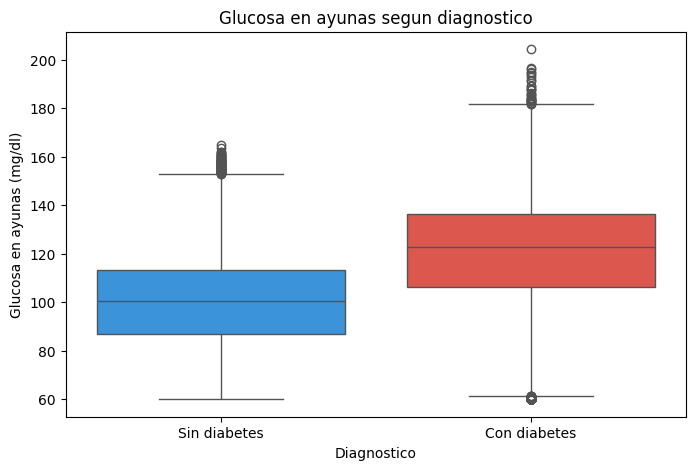

Mediana de cada variable numerica por grupo:
Diagnostico             Con diabetes  Sin diabetes
age                            55.00         47.00
bmi                            31.25         26.79
waist_circumference_cm         91.80         83.10
fasting_glucose_mg_dl         122.70        100.50
hba1c_percent                   4.97          4.67
systolic_bp                   131.00        121.00
diastolic_bp                   82.00         76.00
hdl_mg_dl                      48.90         53.90
triglycerides_mg_dl           185.70        154.60

% de cada condicion por grupo:
Diagnostico              Con diabetes  Sin diabetes
family_history_diabetes          63.3          33.4
hypertension                     71.2          40.3
sex                              51.3          47.8


In [38]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=datos, x="Diagnostico", y="fasting_glucose_mg_dl", hue="Diagnostico",
            palette=colores, legend=False)
plt.title("Glucosa en ayunas segun diagnostico")
plt.xlabel("Diagnostico")
plt.ylabel("Glucosa en ayunas (mg/dl)")
plt.show()

#Comparacion de medianas y promedios entre grupos
print("Mediana de cada variable numerica por grupo:")
print(datos.groupby("Diagnostico")[variables_numericas].median().round(2).T)
print("")
print("% de cada condicion por grupo:")
print((datos.groupby("Diagnostico")[["family_history_diabetes", "hypertension", "sex"]].mean() * 100).round(1).T)

* **Patrón:** la mediana de glucosa en ayunas es 122.7 mg/dl en pacientes con diabetes frente a 100.5 mg/dl sin diabetes, y casi toda la caja del grupo con diabetes está por encima. La tabla de medianas confirma diferencias en todas las variables: el grupo con diabetes tiene más edad (55 vs 47 años), mayor IMC (31.3 vs 26.8), mayor cintura, presión más alta (131 vs 121 mm Hg), triglicéridos más altos y HDL más bajo. Además el 63% tiene antecedente familiar (vs 33%) y el 71% hipertensión (vs 40%).
* **Información:** compara mediana, dispersión y atípicos de los dos grupos en una sola figura.
* **Limitación:** el boxplot resume los datos y oculta cuántos pacientes hay en cada zona; que las medianas sean distintas no prueba causalidad.

### 3.D Mapa de calor de correlaciones

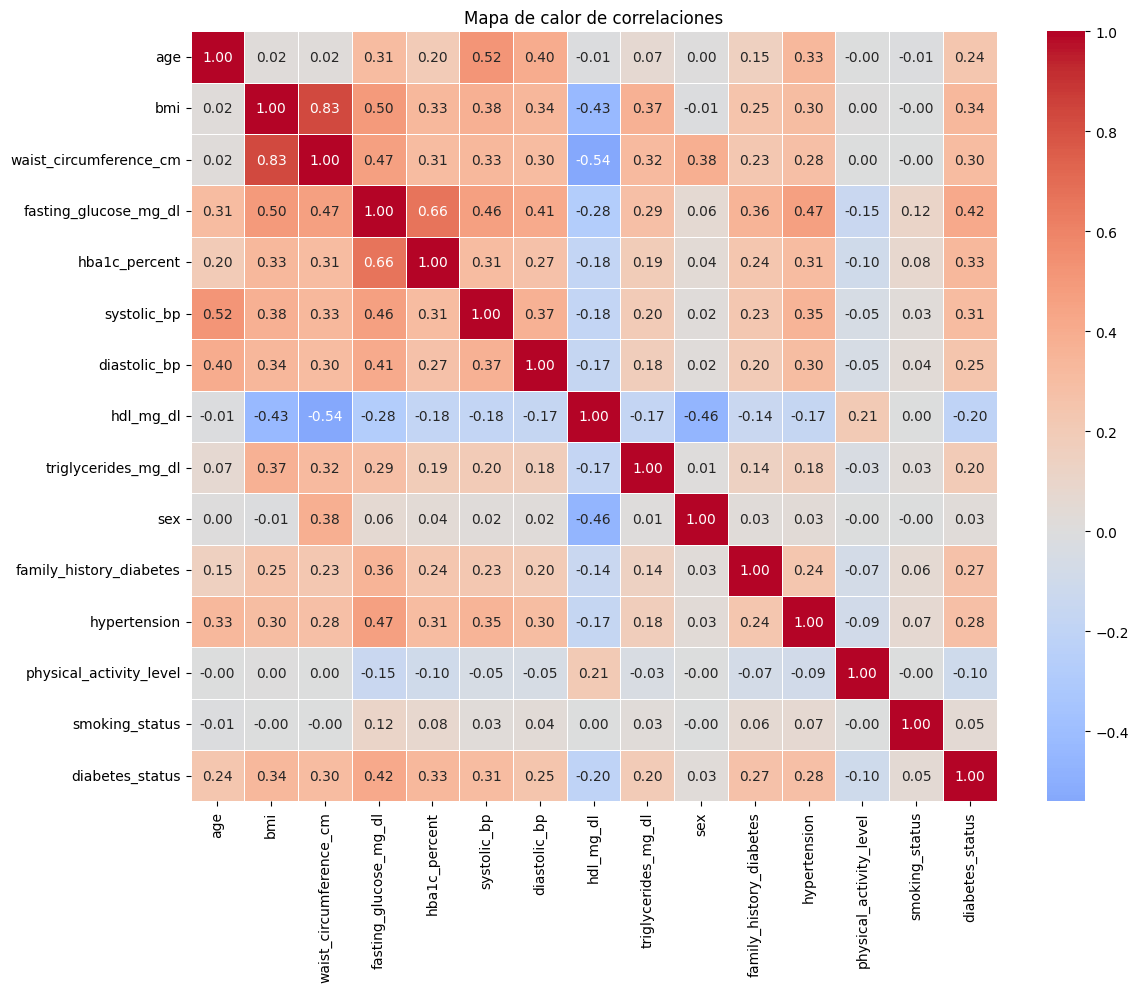

Correlacion con diabetes_status
fasting_glucose_mg_dl      0.421
bmi                        0.336
hba1c_percent              0.327
systolic_bp                0.311
waist_circumference_cm     0.305
hypertension               0.278
family_history_diabetes    0.271
diastolic_bp               0.248
age                        0.241
triglycerides_mg_dl        0.201
smoking_status             0.053
sex                        0.031
physical_activity_level   -0.102
hdl_mg_dl                 -0.203
Name: diabetes_status, dtype: float64


In [39]:
correlacion = datos[variables_modelo + [objetivo]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Mapa de calor de correlaciones")
plt.show()

#Ranking de variables segun su correlacion con el objetivo
print("Correlacion con", objetivo)
print(correlacion[objetivo].drop(objetivo).sort_values(ascending=False).round(3))

* **Patrón:** la glucosa en ayunas es la variable con mayor correlación con el objetivo (0.42), seguida de IMC (0.34), HbA1c (0.33), presión sistólica (0.31) y cintura (0.31). El HDL tiene correlación negativa (-0.20): más colesterol "bueno", menos diabetes. Sexo (0.03) y tabaquismo (0.05) casi no se relacionan. Entre predictoras, IMC y cintura están muy relacionadas, igual que sistólica y diastólica, porque miden casi lo mismo.
* **Información:** indica qué variables tienen mayor relación lineal con el objetivo y cuáles predictoras están muy relacionadas entre sí.
* **Limitación:** Pearson solo mide relaciones lineales y no implica causalidad; en variables categóricas codificadas (como actividad física) la correlación es solo aproximada.

### 3.E Dispersión de glucosa en ayunas vs IMC por grupo

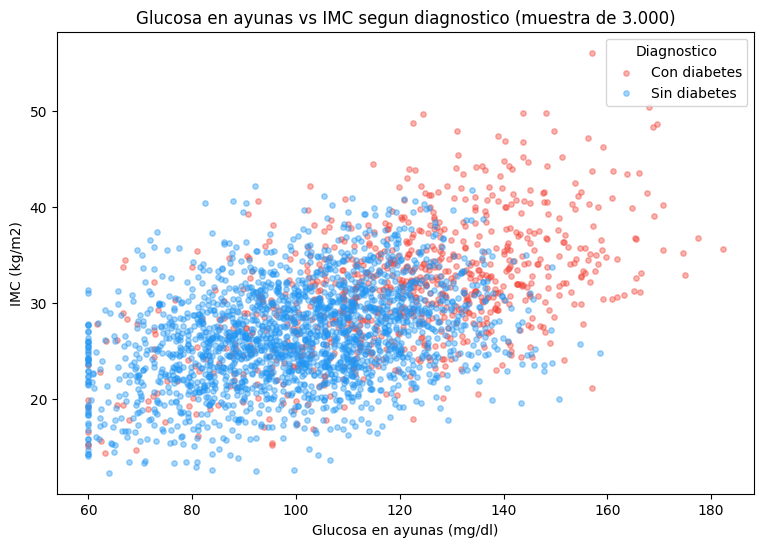

In [40]:
#Con casi 100.000 pacientes los puntos se tapan; se toma una muestra aleatoria de 3.000
muestra = datos.sample(3000, random_state=semilla)

plt.figure(figsize=(9, 6))

for etiqueta, grupo in muestra.groupby("Diagnostico"):
    plt.scatter(grupo["fasting_glucose_mg_dl"], grupo["bmi"], alpha=0.4,
                label=etiqueta, color=colores[etiqueta], s=15)

plt.title("Glucosa en ayunas vs IMC segun diagnostico (muestra de 3.000)")
plt.xlabel("Glucosa en ayunas (mg/dl)")
plt.ylabel("IMC (kg/m2)")
plt.legend(title="Diagnostico")
plt.show()

* **Patrón:** los puntos rojos (con diabetes) se concentran en la zona de glucosa e IMC altos (arriba a la derecha) y los azules en la zona baja. Por encima de ~140 mg/dl de glucosa predominan los rojos, pero en la franja de 100–130 mg/dl los dos grupos se mezclan mucho. Se ve también una columna vertical de puntos en 60 mg/dl (el mínimo registrado).
* **Información:** muestra si al combinar dos variables los grupos se separan mejor que con una sola.
* **Limitación:** es una muestra (no todos los pacientes) y solo se ven dos variables a la vez.

### 3.F Gráfica adicional: porcentaje con diabetes por grupo de edad y antecedente familiar

% con diabetes por grupo de edad y antecedente familiar:
family_history_diabetes    No   Yes
age_group                          
18-30                    11.9  18.2
31-40                    12.9  25.9
41-50                    15.9  35.2
51-60                    19.4  44.2
61-70                    23.8  56.1
71-90                    32.4  69.2


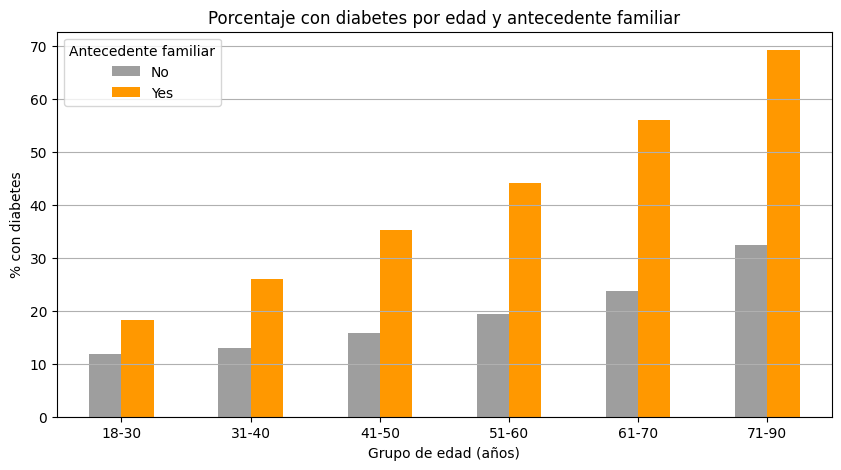

In [41]:
#Se recupera el grupo de edad del dataset original
datos_texto["age_group"] = df.loc[datos_texto.index, "age_group"]
orden_edad = ["18-30", "31-40", "41-50", "51-60", "61-70", "71-90"]

tabla_edad = pd.pivot_table(
    datos_texto,
    values=objetivo,
    index="age_group",
    columns="family_history_diabetes",
    aggfunc="mean"
).reindex(orden_edad) * 100

print("% con diabetes por grupo de edad y antecedente familiar:")
print(tabla_edad.round(1))

tabla_edad.plot(kind="bar", figsize=(10, 5), color=["#9E9E9E", "#FF9800"])
plt.title("Porcentaje con diabetes por edad y antecedente familiar")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("% con diabetes")
plt.xticks(rotation=0)
plt.legend(title="Antecedente familiar")
plt.grid(axis="y")
plt.show()

* **Patrón:** el porcentaje con diabetes aumenta con la edad en ambos grupos, pero mucho más rápido con antecedente familiar: sin antecedente pasa de 12% (18–30 años) a 32% (71–90); con antecedente pasa de 18% a 69%. En todas las edades tener un familiar con diabetes casi duplica el porcentaje de casos.
* **Información:** combina dos factores de riesgo fáciles de preguntar en consulta, sin necesidad de laboratorio.
* **Limitación:** los grupos de edad tienen tamaños distintos (71-90 es el más pequeño) y no se controlan otras variables como el IMC.

## Bloque 4. Modelos de clasificación

### 4.A División 80/20 estratificada

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=semilla,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("")
print("% con diabetes en entrenamiento:", round(y_train.mean() * 100, 2))
print("% con diabetes en prueba:", round(y_test.mean() * 100, 2))

Entrenamiento: (79966, 14)
Prueba: (19992, 14)

% con diabetes en entrenamiento: 28.0
% con diabetes en prueba: 28.0


`stratify=y` mantiene el mismo porcentaje de pacientes con diabetes en entrenamiento y prueba. `random_state=42` hace que la división sea siempre la misma.

### 4.B Transformaciones ajustadas solo con entrenamiento

In [43]:
#1. Rellenar faltantes con la mediana calculada SOLO con entrenamiento
medianas = X_train.median()
print("Medianas de entrenamiento usadas para rellenar:")
print(medianas)

X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)

#2. Escalar: fit solo con entrenamiento, transform en prueba
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("")
print("Faltantes restantes en entrenamiento:", X_train.isnull().sum().sum())
print("Faltantes restantes en prueba:", X_test.isnull().sum().sum())

Medianas de entrenamiento usadas para rellenar:
age                         49.00
bmi                         27.89
waist_circumference_cm      85.30
fasting_glucose_mg_dl      105.50
hba1c_percent                4.75
systolic_bp                124.00
diastolic_bp                78.00
hdl_mg_dl                   52.50
triglycerides_mg_dl        162.80
sex                          0.00
family_history_diabetes      0.00
hypertension                 0.00
physical_activity_level      1.00
smoking_status               0.00
dtype: float64

Faltantes restantes en entrenamiento: 0
Faltantes restantes en prueba: 0


### 4.C Función para evaluar modelos

Una sola función calcula las cuatro métricas y dibuja la matriz de confusión, así todos los modelos se evalúan exactamente igual.

In [44]:
def evaluar_modelo(nombre, y_real, y_pred):
    #Metricas
    resultado = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall": recall_score(y_real, y_pred),
        "F1-score": f1_score(y_real, y_pred)
    }

    #Matriz de confusion
    matriz = confusion_matrix(y_real, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pred: Sin diabetes", "Pred: Con diabetes"],
                yticklabels=["Real: Sin diabetes", "Real: Con diabetes"])
    plt.title("Matriz de confusion - " + nombre)
    plt.xlabel("Prediccion")
    plt.ylabel("Valor real")
    plt.show()

    print("Verdaderos negativos:", matriz[0][0], "| Falsos positivos:", matriz[0][1])
    print("Falsos negativos:", matriz[1][0], "| Verdaderos positivos:", matriz[1][1])

    return resultado

### 4.D Modelo A: Regresión logística

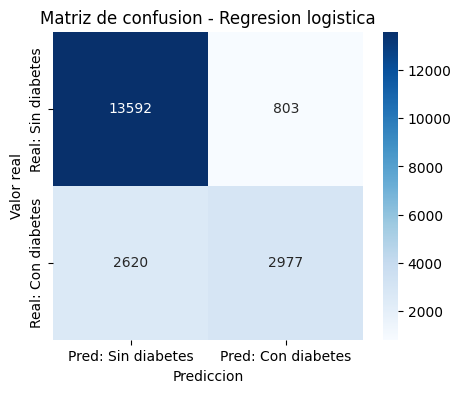

Verdaderos negativos: 13592 | Falsos positivos: 803
Falsos negativos: 2620 | Verdaderos positivos: 2977


In [45]:
modelo_log = LogisticRegression(max_iter=1000, random_state=semilla)
modelo_log.fit(X_train_esc, y_train)

pred_log = modelo_log.predict(X_test_esc)
resultado_log = evaluar_modelo("Regresion logistica", y_test, pred_log)

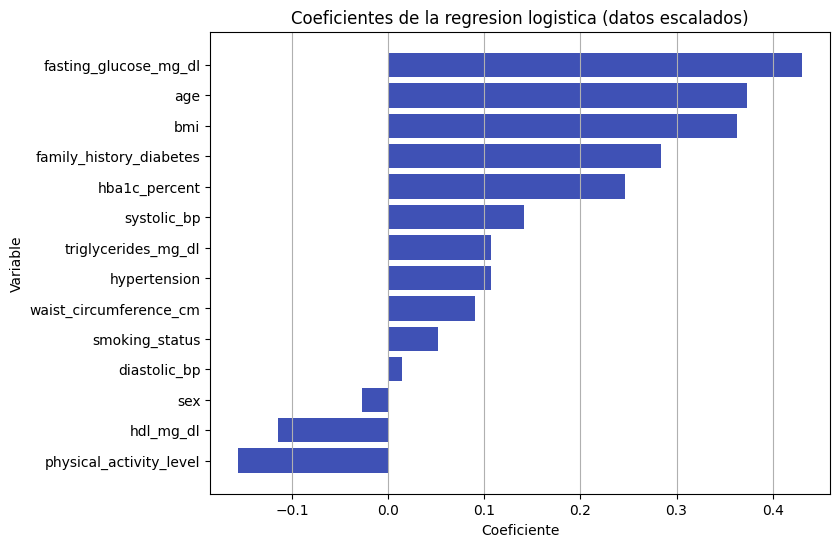

In [46]:
#Coeficientes: indican hacia donde empuja cada variable (positivo = mas riesgo)
coeficientes = pd.Series(modelo_log.coef_[0], index=variables_modelo).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(coeficientes.index, coeficientes.values, color="#3F51B5")
plt.title("Coeficientes de la regresion logistica (datos escalados)")
plt.xlabel("Coeficiente")
plt.ylabel("Variable")
plt.grid(axis="x")
plt.show()

### 4.E Modelo B: Árbol de decisión

Se limita la profundidad a 5 niveles (`max_depth=5`). Un árbol sin límite memoriza los datos de entrenamiento (sobreajuste). Los árboles no necesitan escalado, pero se usan los mismos datos escalados para comparar con la misma entrada.

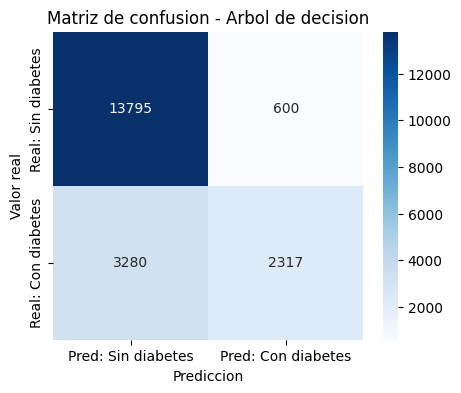

Verdaderos negativos: 13795 | Falsos positivos: 600
Falsos negativos: 3280 | Verdaderos positivos: 2317


In [47]:
modelo_arbol = DecisionTreeClassifier(max_depth=5, random_state=semilla)
modelo_arbol.fit(X_train_esc, y_train)

pred_arbol = modelo_arbol.predict(X_test_esc)
resultado_arbol = evaluar_modelo("Arbol de decision", y_test, pred_arbol)

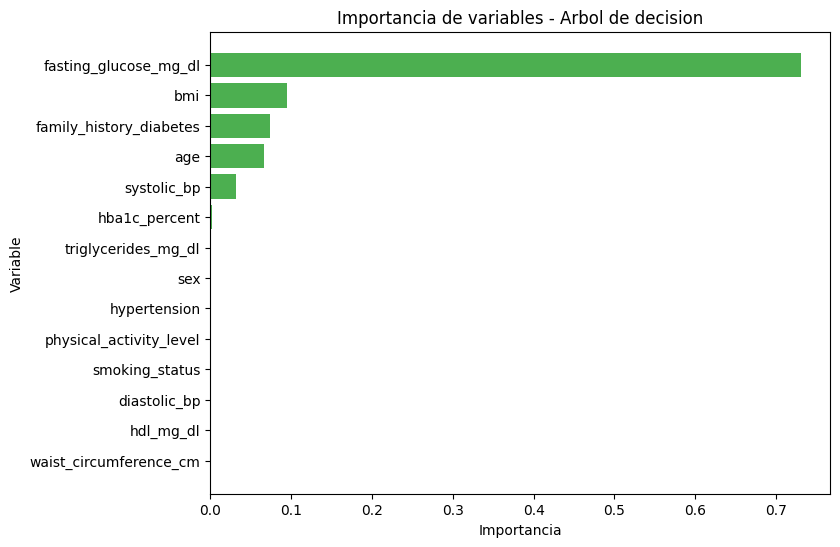

In [48]:
#Variables mas importantes para el arbol
importancia = pd.Series(modelo_arbol.feature_importances_, index=variables_modelo).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importancia.index, importancia.values, color="#4CAF50")
plt.title("Importancia de variables - Arbol de decision")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.show()

### 4.F Comparación en tabla

In [49]:
tabla_modelos = pd.DataFrame([resultado_log, resultado_arbol]).set_index("Modelo").round(3)
tabla_modelos

,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Regresion logistica,0.829,0.788,0.532,0.635
Arbol de decision,0.806,0.794,0.414,0.544


### Reto Bloque 4: ¿qué modelo es más adecuado?

Se elige la **regresión logística** como el modelo tradicional más adecuado.

No se decide solo por accuracy (además, la diferencia es pequeña: 0.829 vs 0.806, y ambos superan el 72% del modelo "siempre sin diabetes" por poco margen). La decisión se basa en las métricas de la clase con diabetes:

* **Recall:** la regresión logística detecta el 53.2% de los pacientes con diabetes; el árbol solo el 41.4%. Es decir, el árbol deja sin detectar 3.280 pacientes con diabetes frente a 2.620 de la regresión.
* **F1-score:** 0.635 vs 0.544, mejor equilibrio entre precisión y recall.
* **Precision:** son casi iguales (0.788 vs 0.794), así que el árbol no compensa su menor recall con menos falsas alarmas.

Además, la regresión logística es estable e interpretable: sus coeficientes muestran que la glucosa en ayunas, el IMC, la HbA1c, la hipertensión y el antecedente familiar empujan hacia diabetes, y el HDL en sentido contrario, lo que coincide con el análisis exploratorio. Su limitación es que con umbral 0.5 todavía no detecta a casi la mitad de los pacientes con diabetes.

## Bloque 5. Red neuronal artificial

Se usan las **mismas 14 variables** y la **misma división** (`X_train_esc`, `X_test_esc`, `y_train`, `y_test`). El preprocesamiento (mediana + escalado) ya se ajustó solo con entrenamiento. Para una red neuronal el escalado es clave porque las variables tienen rangos muy distintos (triglicéridos llegan a 600 y `sex` es 0 o 1).

### 5.A Arquitectura

In [50]:
numero_variables = X_train_esc.shape[1]

red = Sequential()
red.add(Dense(16, activation="relu", input_shape=(numero_variables,)))  #capa oculta 1
red.add(Dense(8, activation="relu"))                                    #capa oculta 2
red.add(Dense(1, activation="sigmoid"))                                 #salida: probabilidad entre 0 y 1

red.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

* **Entrada:** 14 variables.
* **Salida sigmoid con 1 neurona:** entrega la probabilidad de pertenecer al grupo con diabetes.
* **Pérdida `binary_crossentropy`:** la adecuada para clasificación binaria con salida sigmoid.
* **Optimizador `adam`:** ajusta automáticamente la tasa de aprendizaje.
* **`batch_size=256`:** con casi 80.000 pacientes de entrenamiento, lotes más grandes hacen que las 100 épocas terminen en pocos minutos en Colab.

### 5.B Compilar y entrenar

In [51]:
red.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

historial = red.fit(
    X_train_esc,
    y_train,
    epochs=100,
    batch_size=256,
    validation_split=0.2,
    verbose=0
)

print("Entrenamiento terminado:", len(historial.history["loss"]), "epocas")

Entrenamiento terminado: 100 epocas


### 5.C Curvas de pérdida

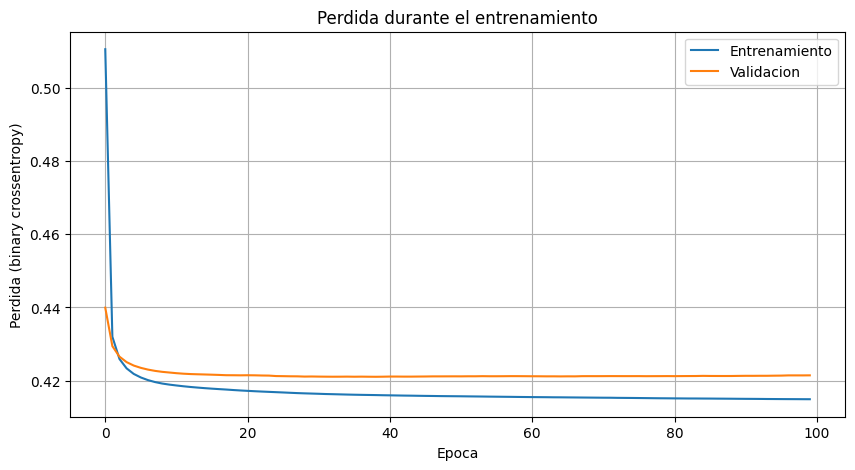

Menor perdida de validacion en la epoca: 39
Perdida minima de validacion: 0.421
Perdida final entrenamiento: 0.4149
Perdida final validacion: 0.4214


In [52]:
plt.figure(figsize=(10, 5))

plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validacion")

plt.title("Perdida durante el entrenamiento")
plt.xlabel("Epoca")
plt.ylabel("Perdida (binary crossentropy)")
plt.legend()
plt.grid()
plt.show()

#Epoca con la menor perdida de validacion
mejor_epoca = np.argmin(historial.history["val_loss"]) + 1
print("Menor perdida de validacion en la epoca:", mejor_epoca)
print("Perdida minima de validacion:", round(min(historial.history["val_loss"]), 4))
print("Perdida final entrenamiento:", round(historial.history["loss"][-1], 4))
print("Perdida final validacion:", round(historial.history["val_loss"][-1], 4))

### 5.D Evaluación en el conjunto de prueba

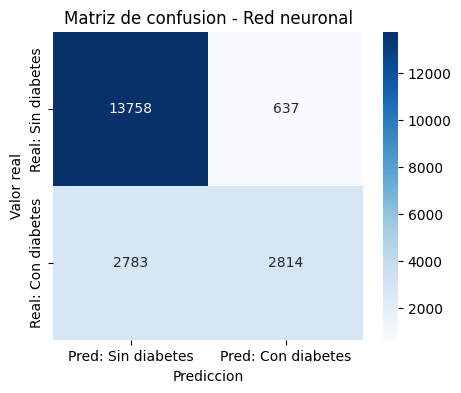

Verdaderos negativos: 13758 | Falsos positivos: 637
Falsos negativos: 2783 | Verdaderos positivos: 2814


In [53]:
#La red entrega probabilidades; con umbral 0.5 se convierten en 0 o 1
prob_red = red.predict(X_test_esc, verbose=0)
pred_red = (prob_red >= 0.5).astype(int).flatten()

resultado_red = evaluar_modelo("Red neuronal", y_test, pred_red)

### 5.E Comparación de los tres modelos

                     Accuracy  Precision  Recall  F1-score
Modelo                                                    
Regresion logistica     0.829      0.788   0.532     0.635
Arbol de decision       0.806      0.794   0.414     0.544
Red neuronal            0.829      0.815   0.503     0.622


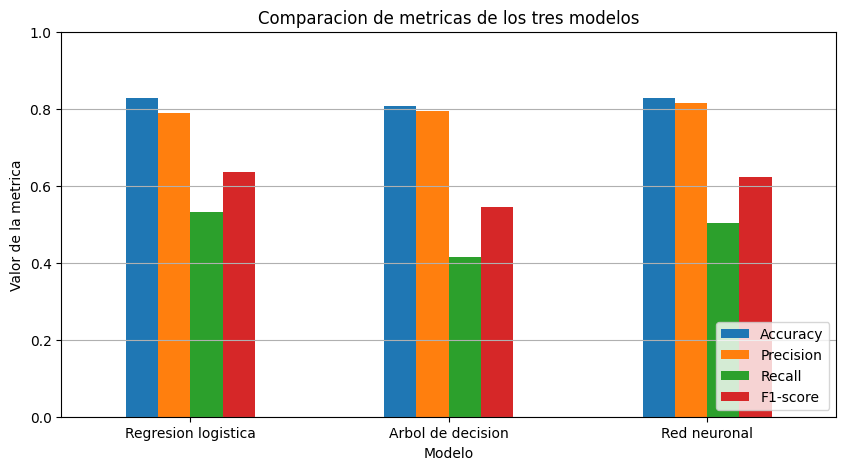

In [54]:
tabla_final = pd.DataFrame([resultado_log, resultado_arbol, resultado_red]).set_index("Modelo").round(3)
print(tabla_final)

tabla_final.plot(kind="bar", figsize=(10, 5))
plt.title("Comparacion de metricas de los tres modelos")
plt.xlabel("Modelo")
plt.ylabel("Valor de la metrica")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

**Comparación:** la red neuronal obtiene accuracy ≈ 0.83, precision ≈ 0.82, recall ≈ 0.50 y F1 ≈ 0.62. Es **competitiva**: queda prácticamente empatada con la regresión logística y supera claramente al árbol de decisión. Tiene la precisión más alta (menos falsas alarmas), pero un recall un poco menor que la regresión logística. Que una red no supere a un modelo lineal indica que la relación entre estas 14 variables y la diabetes es bastante simple; la complejidad extra de la red no aporta mucho.



### Reto Bloque 5: sobreajuste o subajuste

**No hay señales claras de sobreajuste:**

* Las dos curvas bajan rápido en las primeras ~10 épocas y luego se estabilizan.
* La pérdida de validación llega a su mínimo (≈ 0.42) alrededor de la época 30 y después se mantiene casi plana; la distancia con entrenamiento (≈ 0.415 vs ≈ 0.422) es muy pequeña. Con casi 80.000 pacientes y solo 14 variables, la red no tiene capacidad para memorizar.

Lo que se observa es más bien un **leve subajuste / techo de desempeño**: ambas curvas se aplanan en el mismo valor desde temprano, es decir, la red ya aprendió todo lo que estas 14 variables permiten aprender. Las épocas después de la ~30 no aportan nada.

**Mejoras propuestas:**
 **Ajustar el umbral de decisión** (implementada abajo): con umbral 0.5 la red es muy conservadora y deja pasar la mitad de los casos. Bajar el umbral aumenta el recall, que es lo más importante en prevención.


In [55]:
#Mejora propuesta: bajar el umbral de decision para detectar mas pacientes con diabetes
print("Umbral | Accuracy | Precision | Recall | F1")
for umbral in [0.5, 0.4, 0.3]:
    pred_umbral = (prob_red >= umbral).astype(int).flatten()
    print(umbral, "|",
          round(accuracy_score(y_test, pred_umbral), 3), "|",
          round(precision_score(y_test, pred_umbral), 3), "|",
          round(recall_score(y_test, pred_umbral), 3), "|",
          round(f1_score(y_test, pred_umbral), 3))

Umbral | Accuracy | Precision | Recall | F1
0.5 | 0.829 | 0.815 | 0.503 | 0.622
0.4 | 0.827 | 0.762 | 0.554 | 0.642
0.3 | 0.81 | 0.679 | 0.609 | 0.642


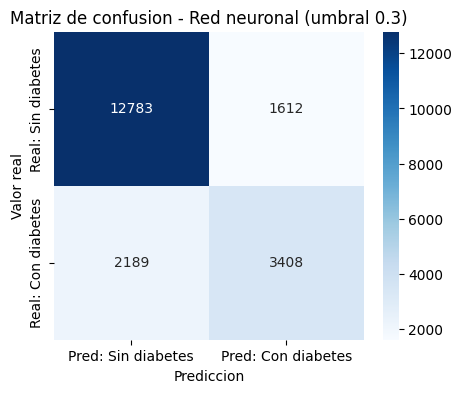

Verdaderos negativos: 12783 | Falsos positivos: 1612
Falsos negativos: 2189 | Verdaderos positivos: 3408


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Red neuronal,0.829,0.815,0.503,0.622
Red neuronal (umbral 0.3),0.810,0.679,0.609,0.642


In [56]:
#Se evalua la red con el umbral 0.3 usando la misma funcion
pred_red_03 = (prob_red >= 0.3).astype(int).flatten()
resultado_red_03 = evaluar_modelo("Red neuronal (umbral 0.3)", y_test, pred_red_03)

pd.DataFrame([resultado_red, resultado_red_03]).set_index("Modelo").round(3)

**Resultado de la mejora:** al bajar el umbral de 0.5 a 0.3 el recall sube de ≈ 0.50 a ≈ 0.61 (se detectan unos 670 pacientes con diabetes más) y el F1 sube de ≈ 0.62 a ≈ 0.65, que es el mejor F1 de todo el parcial. El costo es que la precisión baja (≈ 0.82 → ≈ 0.68) y aparecen más falsas alarmas. En un sistema de **prevención** ese intercambio es razonable: un falso positivo solo implica una prueba de confirmación adicional, mientras que un falso negativo deja a un paciente sin seguimiento.

## Respuestas a las preguntas del enunciado

**1. ¿Qué características presenta la población?** 99.958 pacientes con objetivo válido, de 18 a 90 años (mediana 50), 51% mujeres. La mediana de IMC es 27.9 (rango de sobrepeso) y la de glucosa en ayunas es 105.6 mg/dl. El 28% pertenece al grupo con diabetes. El dataset tiene 209 columnas, 43 con faltantes (entre 2% y 10%, excepto edad de menopausia con 82%), y algunos valores inválidos.

**2. ¿Existen diferencias entre los grupos?** Sí. El grupo con diabetes tiene mayor glucosa en ayunas (mediana 122.7 vs 100.5 mg/dl), mayor IMC, más edad, presión más alta, triglicéridos más altos, HDL más bajo, y mucho más antecedente familiar (63% vs 33%) e hipertensión (71% vs 40%).

**3. ¿Qué variables tienen mayor relación con el objetivo?** Glucosa en ayunas (r = 0.42), IMC (0.34), HbA1c (0.33), presión sistólica (0.31) y cintura (0.31). Sexo y tabaquismo casi no tienen relación.

**4. ¿Qué modelo ofrece mejores resultados?** Entre los tradicionales, la regresión logística (recall 0.532, F1 0.635), muy por encima del árbol en recall.

**5. ¿La red neuronal es competitiva?** Sí: empata con la regresión logística (F1 ≈ 0.62, accuracy ≈ 0.83) y supera al árbol. Con umbral 0.3 alcanza el mejor F1 (≈ 0.65), pero no gana por su arquitectura sino por el ajuste del umbral, que también se podría aplicar a la regresión logística.

## Bloque 6. Informe ejecutivo

**Hallazgos del análisis exploratorio.** El dataset tiene 100.000 registros y 209 columnas. No hubo duplicados, pero sí faltantes en 43 columnas y valores inválidos: presiones sistólicas menores que la diastólica, IMC menores a 12 y 200 registros con glucosa mayor a 250 mg/dl y HbA1c mayor a 10% que en su mayoría figuraban sin diabetes. Estos valores se marcaron como faltantes sin eliminar filas. El objetivo `diabetes_status` se recuperó con `diabetes_type` cuando faltaba, quedando 99.958 pacientes, con 28% en el grupo con diabetes. Se descartaron columnas con fuga de información (medicamentos, complicaciones y puntajes de riesgo) y se usaron 14 predictoras. La glucosa en ayunas es la variable que más separa los grupos (mediana 122.7 vs 100.5 mg/dl; r = 0.42), seguida de IMC, HbA1c, presión sistólica y cintura. El antecedente familiar casi duplica la proporción de casos en todas las edades.

**Mejor modelo.** Entre los modelos tradicionales, la regresión logística superó al árbol de decisión en recall (0.532 vs 0.414) y F1-score (0.635 vs 0.544). La red neuronal obtuvo resultados casi iguales a la regresión logística (accuracy ≈ 0.83, F1 ≈ 0.62), sin sobreajuste. El mejor resultado global lo dio la red con umbral 0.3 (F1 ≈ 0.65, recall ≈ 0.61). Se privilegió el F1 y el recall porque, con clases desbalanceadas, el accuracy es engañoso: decir siempre "sin diabetes" ya da 72%.

**Errores según la matriz de confusión.** Con umbral 0.5, la regresión logística tuvo 2.977 verdaderos positivos, 803 falsos positivos y 2.620 falsos negativos sobre 19.992 pacientes de prueba. El error dominante son los **falsos negativos**: casi la mitad de los pacientes con diabetes se clasifican como sanos. Bajar el umbral reduce ese error a costa de más falsas alarmas.

**Limitaciones del dataset.** Los datos parecen sintéticos: la HbA1c casi nunca supera 6.5%, valor que en la práctica define la diabetes; miles de glucosas están fijadas en 60 mg/dl, y hay columnas redundantes y etiquetas cortadas como "Non-Bi". Muchas variables están tan ligadas al diagnóstico que debieron excluirse. El relleno con medianas reduce la variabilidad real y no hay información temporal para saber qué ocurrió antes del diagnóstico.

**Por qué no es un diagnóstico médico.** El modelo solo encuentra patrones estadísticos en un conjunto de datos limitado y posiblemente simulado; no reemplaza pruebas clínicas validadas ni el criterio de un profesional de la salud. Incluso el mejor modelo deja sin detectar cerca de 4 de cada 10 pacientes con diabetes. Es un ejercicio académico de clasificación, no una herramienta para decisiones clínicas.